# Gold / Govt Bond / G10 FX Time-Series Momentum: Research Notebook
**Structure:**  Introduction → Methodology → Findings → Appendix (exploratory) → Key Takeaways → Verdict. 

This notebook runs entirely on cached, cleaned data (`data/cleaned/combined_prices.parquet`). 

The `yfinance` pull is separate, located in `scripts/download_data.py`.

## Introduction

**Hypothesis.** 

Trailing 12-month return sign predicts near-term future return sign: the classic time-series
momentum (TSMOM) effect. This is the effect described in **Moskowitz, Ooi & Pedersen (2012), "Time Series
Momentum," *Journal of Financial Economics***, which is also the source for the signal design (`sign` of trailing
return) and the volatility-scaling approach used throughout this notebook. I test whether this persistence is
present and profitable net of realistic costs in a small, liquid, macro-diversified basket spanning
three asset classes: commodities, government bonds and currencies.

**Universe:** 

GLD (Gold), IEF (Govt Bonds ETF) and EURUSD / GBPUSD / USDJPY (G10 FX). Five independent legs
combined into one unified strategy. 

Gold is an inflation and safe-haven hedge. 

IEF is 7-10yr Treasury duration and rate-cycle exposure. 

The three FX pairs are the most heavily-traded G10 currencies by BIS Triennial Survey volume and IMF reserve-currency share, alongside USD itself. 

They were not picked based on how they performed in this backtest but because they of their significance and liquidity, since they are the most widely transacted assets.

**A caveat on "five independent legs":** 

three of the five are FX pairs quoted against USD. This is a source of
shared risk the earlier GLD/IEF/EURUSD version of this basket did not have. The USD is thus able to 
strengthen or weaken against everything at once, so it can push all three FX legs' trends in the same direction.
As such this is not full diversification even though the three pairs are different currencies. The realised correlation
between all five legs' daily returns is computed and shown after the data loads below, so this is checked
empirically.

**Data source note.** 

I had access to back-adjusted continuous futures for gold and Treasuries, but chose not to use them. Their history
stopped in 2016, and because they are difference-back-adjusted their price level is not on a real-dollar scale, so
extending them with outside data would need return-rebasing rather than a simple join (see `reports/source_note.md`).

Gold and the govt-bond leg instead use GLD/IEF via yfinance, from 2004 to present.
For the three FX legs, this run used a vendor spot-FX history through 2016-12-30, concatenated with its yfinance
continuation from 2017 onward. Both sides are real spot rates in the same units, so no rebasing is needed, only a
boundary sanity check (`src/data_pipeline.py::load_fx_spliced`). The vendor files are not included in this repo, so
re-running the pipeline without them uses yfinance for the full FX history.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data_pipeline as dp
from src import signal as sig
from src import portfolio as pf
from src import backtest as bt
from src import metrics as mx
from src import charts as ch

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

NOTIONAL = 1_000_000.00  # assumed notional for dollar-cost figures


## Methodology

### Data

**Prices:** 

Adjusted close for GLD, IEF, EURUSD, GBPUSD and USDJPY. Adjusted close is used instead of raw close
  because dividends and distributions are material for the bond ETF (IEF pays regular coupon-derived
  distributions). This is kept consistent for GLD and the three FX legs that all don't have dividends and has no effect.

**History:** 

Maximum overlapping history. GLD IPO'd Nov 2004, so the combined series starts 2004-11-18. This is
  the binding constraint even though the FX legs' own histories go back further to 1991 and IEF to earlier in 2004.

**Cleaning:** 

Duplicates, missing observations and non-positive / stale prices are checked and logged in
  (`src/data_pipeline.py::validate_prices`) and are never filled. The five legs are aligned on the intersection
  of trading dates are dropped and not forward-filled. 

**Caching:** 

Cleaned combined prices are cached to `data/cleaned/combined_prices.parquet`.


In [2]:
prices = dp.load_cached_prices()
with open("../data/cleaned/cleaning_log.json") as f:
    cleaning_log = json.load(f)

print(f"Combined price history: {prices.index.min().date()} to {prices.index.max().date()} "
      f"({len(prices)} trading days)")
dropped = {leg: cleaning_log['alignment'][f'{leg}_dropped_dates'] for leg in prices.columns}
print(f"Alignment: {cleaning_log['alignment']['common_dates']} common dates; dropped {dropped} "
      f"(non-overlapping trading days on each leg's own calendar, dropped not filled)")
prices.tail(3)


Combined price history: 2004-11-18 to 2026-08-18 (5466 trading days)
Alignment: 5466 common dates; dropped {'GLD': 4, 'IEF': 226, 'EURUSD': 1715, 'GBPUSD': 3782, 'USDJPY': 3782} (non-overlapping trading days on each leg's own calendar, dropped not filled)


,GLD,IEF,EURUSD,GBPUSD,USDJPY
Date,,,,,
2026-08-14,401.4800,93.0400,1.1535,1.3491,159.4260
2026-08-17,405.4900,92.8400,1.1574,1.3547,159.2230
2026-08-18,398.5500,92.9300,1.1583,1.3550,159.3400


### Leg correlation (diversification check)

Compute daily-return correlation across all five legs for the full sample.

This is the direct check on the caveat that EURUSD/GBPUSD/USDJPY share USD exposure and might not be as independent as five
different instruments suggests.


In [3]:
leg_returns = prices.pct_change()
corr = leg_returns.corr()
display(corr)

fx_legs = [c for c in prices.columns if c in ("EURUSD", "GBPUSD", "USDJPY")]
fx_corr_pairs = corr.loc[fx_legs, fx_legs].where(~np.eye(len(fx_legs), dtype=bool)).stack()
print(f"\nFX-leg pairwise correlations (USD-common-side check): "
      f"{ {f'{a}-{b}': round(v, 2) for (a, b), v in fx_corr_pairs.items() if a < b} }")
print(f"Mean |corr| among the 3 FX legs: {fx_corr_pairs.abs().mean():.2f}")
print(f"Mean |corr| between GLD/IEF and the FX legs: "
      f"{corr.loc[['GLD','IEF'], fx_legs].abs().values.mean():.2f}")


,GLD,IEF,EURUSD,GBPUSD,USDJPY
GLD,1.0000,0.2063,0.2467,0.1724,-0.1444
IEF,0.2063,1.0000,0.0013,-0.0313,-0.2931
EURUSD,0.2467,0.0013,1.0000,0.6433,-0.3041
GBPUSD,0.1724,-0.0313,0.6433,1.0000,-0.1823
USDJPY,-0.1444,-0.2931,-0.3041,-0.1823,1.0000



FX-leg pairwise correlations (USD-common-side check): {'EURUSD-GBPUSD': 0.64, 'EURUSD-USDJPY': -0.3, 'GBPUSD-USDJPY': -0.18}
Mean |corr| among the 3 FX legs: 0.38
Mean |corr| between GLD/IEF and the FX legs: 0.15


### Signal

$$\text{signal}_{leg,t} = \text{sign}\left(\frac{P_t}{P_{t-252}} - 1\right)$$

Trailing 12-month (252 trading day) return, computed independently per leg. Long (+1) if positive, short (-1) if
negative. Sensitivity variants at 189 (about 9 months) and 126 (about 6 months) trading days are computed and
reported side by side in Findings for robustness. They are never used to select a "best" lookback preventing overfitting.

### Position sizing (per leg)

- realised vol: rolling 60-trading-day annualized stdev of daily returns (`daily_std * sqrt(252)`).
- Leg exposure: $w_{leg,t} = \frac{\text{target\_leg\_vol}}{\text{realised\_vol}_{leg,t}} \times \text{signal}_{leg,t}$,
  with `target_leg_vol = target_portfolio_vol / 5` (2% each, one fifth per leg). `combine_portfolio_primary`
  automatically divides by `len(legs)`.

### Portfolio combination: PRIMARY 

Deterministic, three-step inverse volatility combination (`src/portfolio.py::combine_portfolio_primary`):

1. Per-leg vol-targeted weights (above), summed across legs.
2. Portfolio-level vol scale, computed from the trailing 60-day realised vol of the CURRENT-weight
   portfolio. 
3. 2x gross exposure cap: if $\sum|w_{leg}| > 2.0$, scale all legs down proportionally
   by $2.0 / \sum|w_{leg}|$. One `min()`-style deterministic operation.

Because diversification usually pulls combined vol below the 10% target, step 2 levers the book up in calm
regimes. The full gross-exposure time series is reported below so this is visible. When the 2x cap binds, realised
portfolio vol runs below the 10% target. This is an expected (bounding worst-case leverage). 
With five legs instead of three and three of those five sharing USD exposure, the cap is expected to bind more often than the original 3-leg basket. 
The percentage of rebalances where it binds and the average gross exposure with and without the cap are reported in Findings.

### Portfolio combination: APPENDIX

Correlation-adjusted equal-risk-contribution (ERC) weights using the trailing 60-day covariance matrix
(`src/portfolio.py::combine_portfolio_risk_parity_appendix`). Shown only as a supplementary comparison in the
Appendix section. 

### Rebalance and execution

- Weekly rebalance: weights recomputed at the last trading day of each calendar week.
- No lookahead: the weight decided using data through rebalance date $t$ is applied to the return realised on
  day $t+1$ (`applied_weights = daily_weights.shift(1)`, flagged explicitly in `src/backtest.py`). The same shift
  is applied to transaction costs, which are realised the day the new position starts affecting P&L.

### Costs

| Leg | One-way tx cost (bps) | Bracket used |
|---|---|---|
| GLD | 7 | Commodity ETF bracket |
| IEF | 3 | Liquid rates-ETF bracket |
| EURUSD | 2 | Spot FX bid/ask on the most liquid G10 pair, conservative round number |
| GBPUSD | 2 | Same spot FX bracket, applied across all three FX legs |
| USDJPY | 2 | Same spot FX bracket, applied across all three FX legs |

Annualised ETF expense ratios (daily drag, proportional to `|weight|`): **GLD 0.40%, IEF 0.15%, EURUSD, GBPUSD
and USDJPY 0%** each (spot FX has no fund wrapper or expense ratio). Gross versus net is reported at both the
transaction-cost-only level and the all-in level.

Borrow and leverage-financing cost disclosure.  This is a
long-short book with vol targeting and a 2x gross cap, so it can run gross exposure up to 200% and hold short
legs. Borrow and financing costs are excluded from the modeled cost lines (headline numbers use only the tx costs
and expense ratios above). These are computed quantitatively below once the backtest has run, using the
strategy's actual average gross exposure.


### Chronological train and test split

- **Development:** 2005-01-01 to 2015-12-31 

- **Out-of-sample (rules frozen, unchanged):** 

2016-01-01 to the latest available date, about 10 years, well past
  the 5-year OOS minimum I set myself. No parameter is re-fit, re-optimized or re-selected using OOS-period data:
  the 12-month lookback and the vol-scaling and sizing formulas from the development period carry forward
  unchanged into OOS.

"rolling walk-forward": 

The rolling element is the weekly re-estimation of realised vol and position
sizing, which only ever uses trailing or past data.

It re-estimates every rebalance, using only information available at that point in time, all the way through the 10-year OOS window. The signal
parameters themselves are deliberately never re-fit. Re-optimizing a single 12-month lookback on about 10 years
of weekly data would be a parameter search on the sample. Position sizing rolls forward and signal parameters stay fixed from the
development period to preserve out-of-sample integrity.

### Regime split (within OOS only)

Rolling 60-day realised vol of the strategy's own combined daily return is computed within the OOS window and
split at the median into High-Vol and Low-Vol subsets.

### Benchmark

Static buy-and-hold basket: fixed equal weight per leg (1/5 each with five legs), no signal or vol targeting.

## Findings

In [4]:
DEV_START, DEV_END = pd.Timestamp("2005-01-01"), pd.Timestamp("2016-01-01")
OOS_START, OOS_END = pd.Timestamp("2016-01-01"), prices.index.max() + pd.Timedelta(days=1)

primary_signal = sig.tsmom_signal(prices, lookback=sig.PRIMARY_LOOKBACK)
all_signals = sig.all_lookback_signals(prices)  # 6mo, 9mo, 12mo: sensitivity only

result = bt.run_backtest(prices, primary_signal)
benchmark = bt.run_benchmark(prices)

print(f"Signal available from {primary_signal.dropna().index.min().date()} "
      f"(252-trading-day warm-up from series start)")
print(f"Weekly rebalances: {len(result['weekly_weights'])}")


Signal available from 2005-11-17 (252-trading-day warm-up from series start)
Weekly rebalances: 1084


### Charts

Cumulative performance vs benchmark, drawdown, rolling Sharpe/returns and signal/position, followed by one
diagnostic regime chart below.


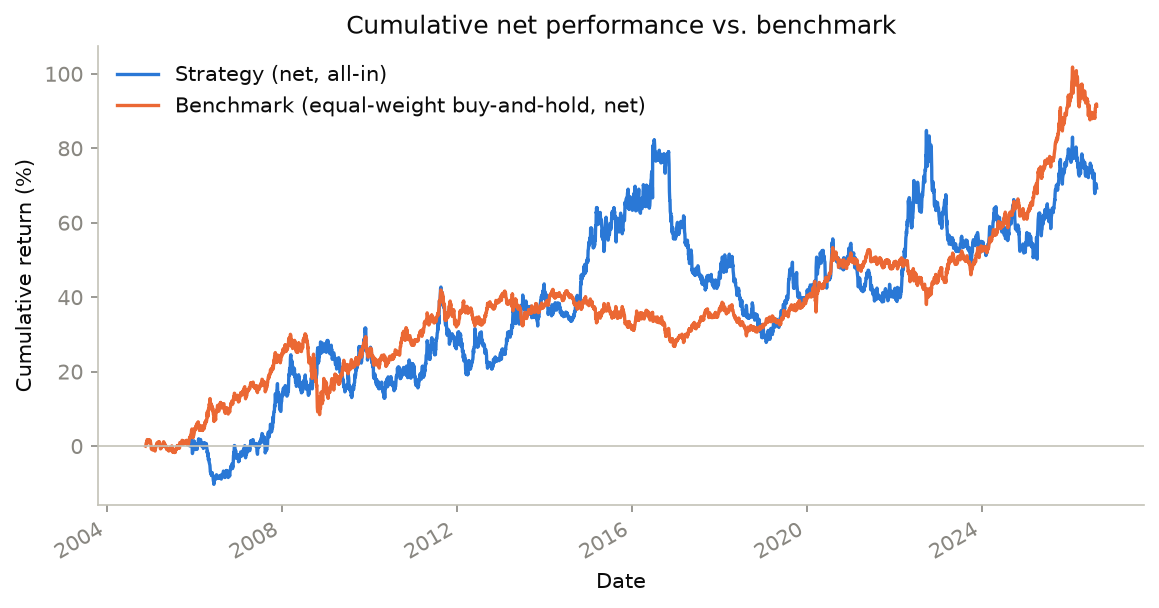

In [5]:
fig = ch.plot_cumulative_vs_benchmark(result["net_all_in_return"], benchmark["net_all_in_return"])
ch.show_fig(fig)


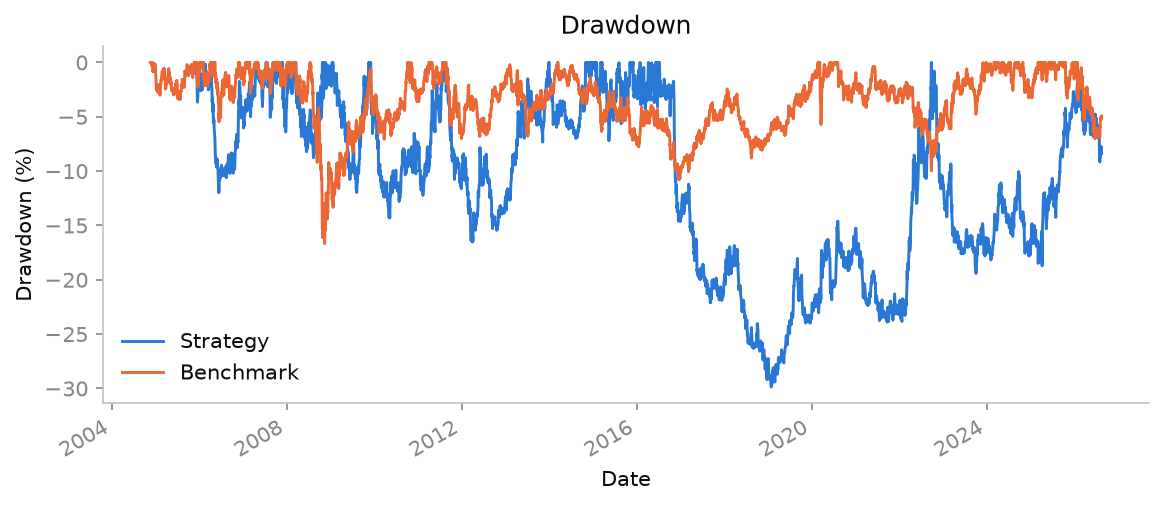

In [6]:
fig = ch.plot_drawdown(result["net_all_in_return"], benchmark["net_all_in_return"])
ch.show_fig(fig)


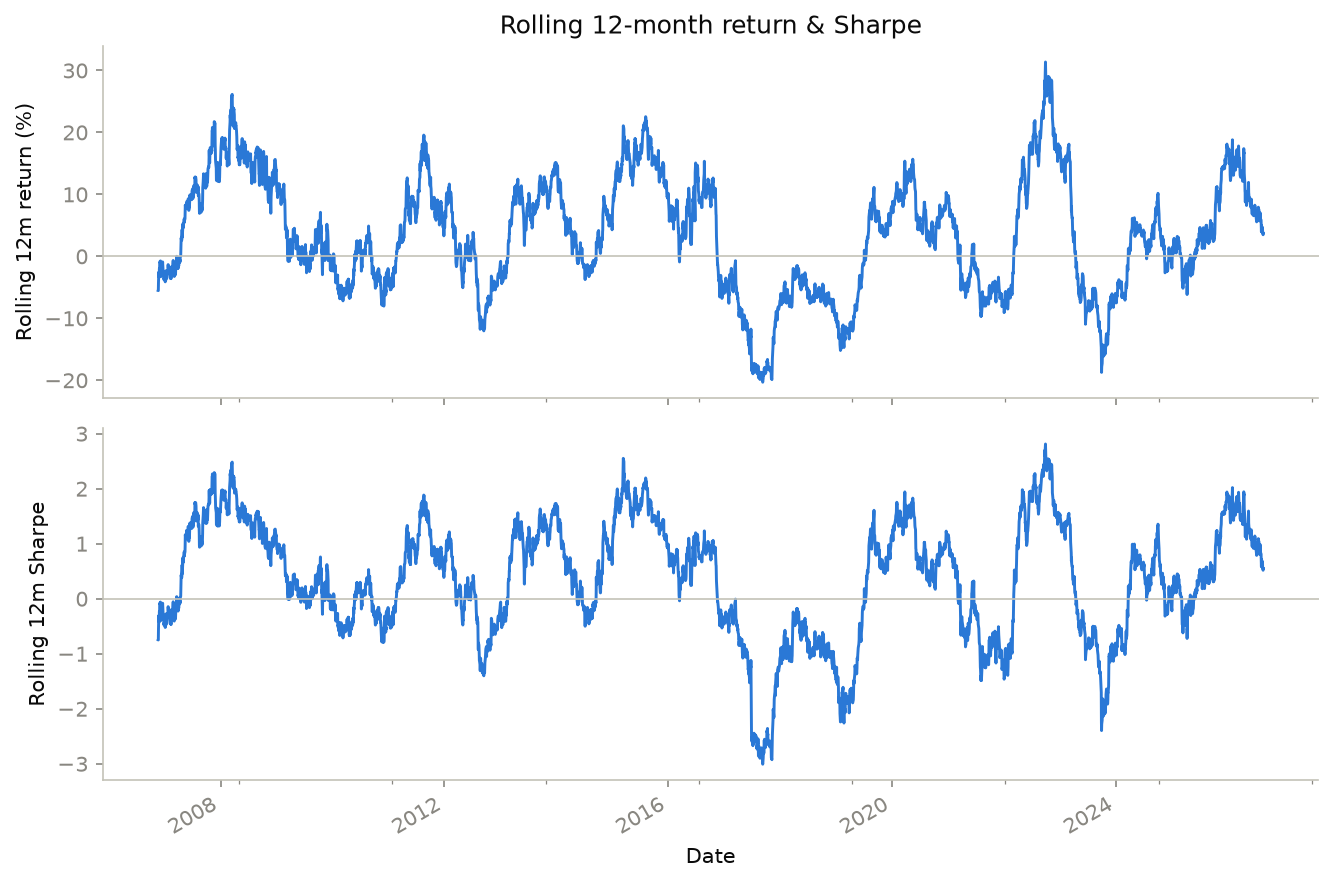

In [7]:
fig = ch.plot_rolling_sharpe_and_return(result["net_all_in_return"])
ch.show_fig(fig)


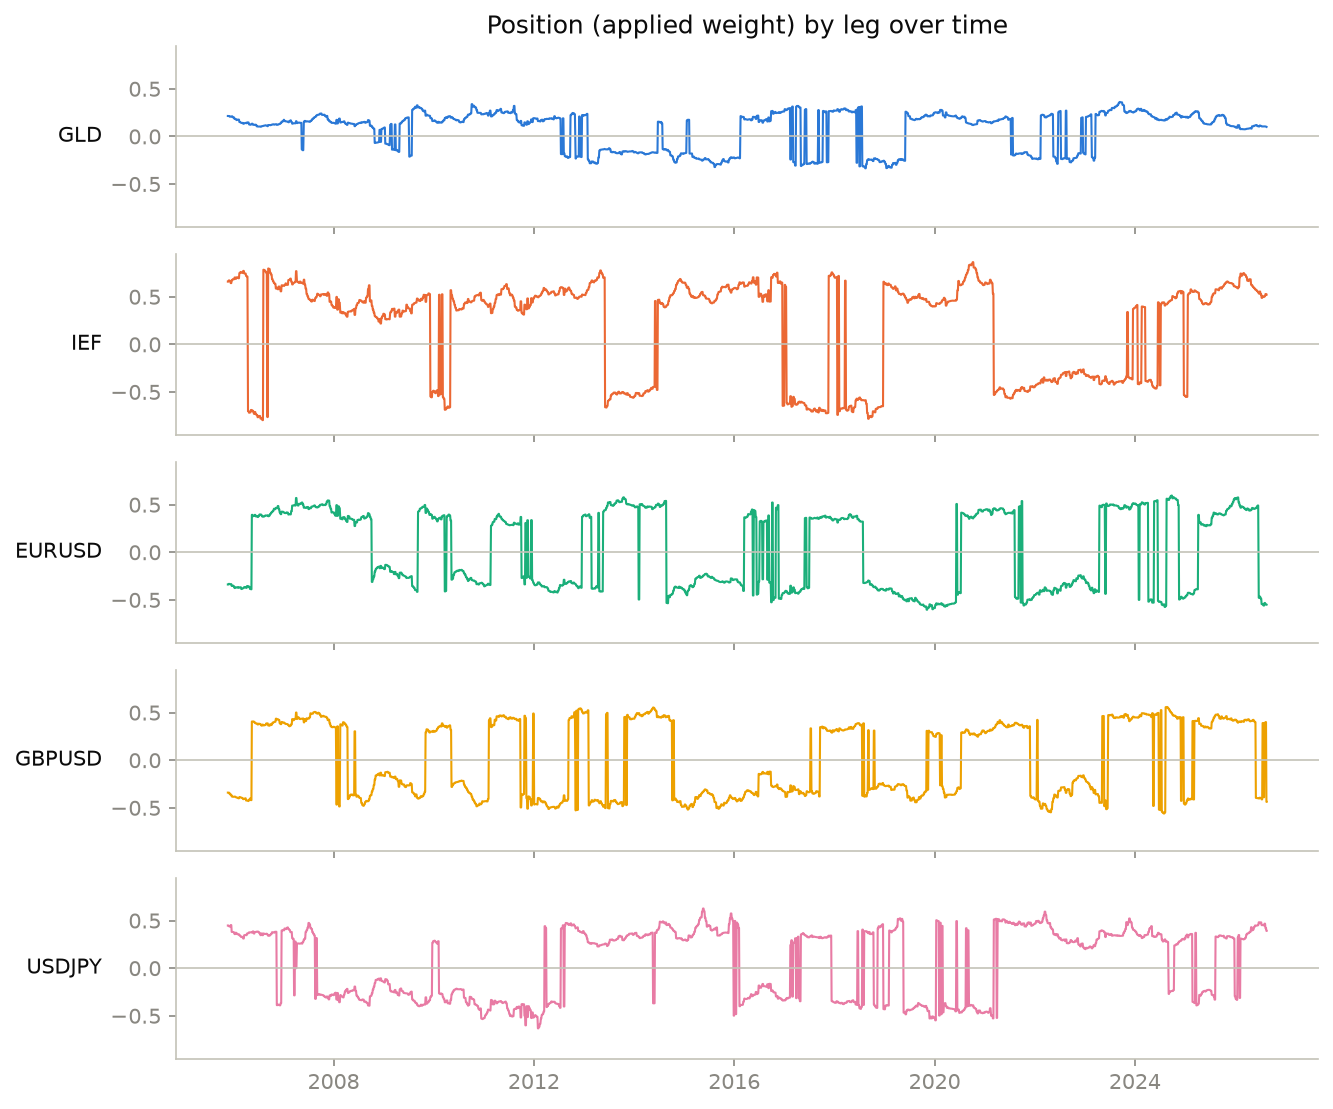

In [8]:
fig = ch.plot_positions(result["applied_weights"])
ch.show_fig(fig)


In [9]:
dev_metrics = mx.compute_period_metrics(result, primary_signal, DEV_START, DEV_END, notional=NOTIONAL)
oos_metrics = mx.compute_period_metrics(result, primary_signal, OOS_START, OOS_END, notional=NOTIONAL)

regimes = mx.regime_masks(result["gross_return"], OOS_START, OOS_END)
oos_high_metrics = mx.compute_period_metrics(result, primary_signal, dates_index=regimes["high_vol_dates"], notional=NOTIONAL)
oos_low_metrics = mx.compute_period_metrics(result, primary_signal, dates_index=regimes["low_vol_dates"], notional=NOTIONAL)

bench_dev_metrics = mx.compute_period_metrics(benchmark, primary_signal, DEV_START, DEV_END, notional=NOTIONAL)
bench_oos_metrics = mx.compute_period_metrics(benchmark, primary_signal, OOS_START, OOS_END, notional=NOTIONAL)

print("--- Strategy: Development period (2005-2015) ---")
display(mx.metrics_table_to_frame(dev_metrics))
print("--- Strategy: Full OOS (2016-latest) ---")
display(mx.metrics_table_to_frame(oos_metrics))
print("--- Strategy: OOS High-Vol regime ---")
display(mx.metrics_table_to_frame(oos_high_metrics))
print("--- Strategy: OOS Low-Vol regime ---")
display(mx.metrics_table_to_frame(oos_low_metrics))
print("--- Benchmark: Development period ---")
display(mx.metrics_table_to_frame(bench_dev_metrics))
print("--- Benchmark: Full OOS ---")
display(mx.metrics_table_to_frame(bench_oos_metrics))

--- Strategy: Development period (2005-2015) ---


,annual_return,annual_vol,sharpe,sortino,max_drawdown,calmar,hit_rate
gross,0.0563,0.0919,0.6120,0.8834,-0.1620,0.3474,0.5234
net_tx,0.0527,0.0920,0.5736,0.8265,-0.1646,0.3205,0.5222
net_all_in,0.0511,0.0920,0.5562,0.8009,-0.1653,0.3095,0.5218


--- Strategy: Full OOS (2016-latest) ---


,annual_return,annual_vol,sharpe,sortino,max_drawdown,calmar,hit_rate
gross,0.0086,0.0836,0.1025,0.1504,-0.2814,0.0305,0.5126
net_tx,0.0038,0.0836,0.0460,0.0672,-0.2950,0.0130,0.5099
net_all_in,0.0022,0.0836,0.0259,0.0378,-0.2987,0.0072,0.5088


--- Strategy: OOS High-Vol regime ---


,annual_return,annual_vol,sharpe,sortino,max_drawdown,calmar,hit_rate
gross,-0.0150,0.0976,-0.1531,-0.2271,-0.2435,-0.0614,0.5038
net_tx,-0.0196,0.0976,-0.2004,-0.2965,-0.2557,-0.0765,0.5000
net_all_in,-0.0212,0.0976,-0.2167,-0.3204,-0.2609,-0.0811,0.5000


... (2 outputs left out)

--- Benchmark: Development period ---


,annual_return,annual_vol,sharpe,sortino,max_drawdown,calmar,hit_rate
gross,0.0259,0.0618,0.4187,0.5905,-0.1662,0.1557,0.5222
net_tx,0.0254,0.0618,0.4111,0.5796,-0.1664,0.1526,0.5222
net_all_in,0.0243,0.0618,0.3924,0.5528,-0.1668,0.1454,0.5218


--- Benchmark: Full OOS ---


,annual_return,annual_vol,sharpe,sortino,max_drawdown,calmar,hit_rate
gross,0.0378,0.0494,0.7642,1.0752,-0.0969,0.3897,0.5429
net_tx,0.0373,0.0494,0.7558,1.0630,-0.0976,0.3826,0.5426
net_all_in,0.0362,0.0494,0.7318,1.0282,-0.0997,0.3626,0.5414


In [10]:
print(f"Dev:  {dev_metrics['n_rebalances']} rebalances | avg holding period (days) by leg: "
      f"{ {k: round(v, 1) for k, v in dev_metrics['avg_holding_period_days'].items()} }")
print(f"OOS:  {oos_metrics['n_rebalances']} rebalances | avg holding period (days) by leg: "
      f"{ {k: round(v, 1) for k, v in oos_metrics['avg_holding_period_days'].items()} }")
print(f"OOS turnover: avg weekly {oos_metrics['turnover_avg_weekly']:.3f}, total {oos_metrics['turnover_total']:.1f}")
print(f"OOS total tx cost: {oos_metrics['total_tx_cost_bps_of_notional']:.1f} bps of notional "
      f"(${oos_metrics['total_tx_cost_dollars']:,.0f} on ${NOTIONAL:,.0f} notional)")
print(f"OOS total expense-ratio drag: {oos_metrics['total_expense_bps_of_notional']:.1f} bps "
      f"(${oos_metrics['total_expense_dollars']:,.0f})")
print(f"OOS avg gross exposure: pre-cap {oos_metrics['avg_gross_exposure_precap']:.2f}x, "
      f"post-cap {oos_metrics['avg_gross_exposure_postcap']:.2f}x")
print(f"OOS % of rebalances where the 2x gross cap binds: {oos_metrics['pct_rebalances_cap_binds']*100:.1f}%")


Dev:  529 rebalances | avg holding period (days) by leg: {'GLD': np.float64(53.6), 'IEF': np.float64(84.4), 'EURUSD': np.float64(52.9), 'GBPUSD': np.float64(41.2), 'USDJPY': np.float64(59.2), 'average': 58.3}
OOS:  555 rebalances | avg holding period (days) by leg: {'GLD': np.float64(27.1), 'IEF': np.float64(43.5), 'EURUSD': np.float64(24.4), 'GBPUSD': np.float64(21.6), 'USDJPY': np.float64(19.6), 'average': 27.2}
OOS turnover: avg weekly 0.321, total 178.3
OOS total tx cost: 497.4 bps of notional ($49,738 on $1,000,000 notional)
OOS total expense-ratio drag: 177.2 bps ($17,721)
OOS avg gross exposure: pre-cap 2.75x, post-cap 1.92x
OOS % of rebalances where the 2x gross cap binds: 81.4%


### Verdict determination

In [11]:
oos_sharpe = oos_metrics["net_all_in"]["sharpe"]
oos_sortino = oos_metrics["net_all_in"]["sortino"]
oos_mdd = oos_metrics["net_all_in"]["max_drawdown"]
oos_return = oos_metrics["net_all_in"]["annual_return"]
bench_sharpe = bench_oos_metrics["net_all_in"]["sharpe"]

if oos_sharpe >= 0.5:
    verdict = "PURSUE"
elif oos_sharpe >= 0.2:
    verdict = "MONITOR"
elif oos_sharpe >= -0.1:
    verdict = "PAPER TRADE"
else:
    verdict = "REJECT"

evidence_text = (
    f"OOS (2016-{prices.index.max().year}) net-all-in Sharpe = {oos_sharpe:.2f}, Sortino = {oos_sortino:.2f}, "
    f"annualized return = {oos_return*100:.1f}%, max drawdown = {oos_mdd*100:.1f}%. "
    f"For comparison, the static 1/5-each benchmark achieved net Sharpe {bench_sharpe:.2f} over the same window. "
    f"{'The active strategy did not clear its own costs relative to a passive hold' if oos_sharpe < bench_sharpe else 'The active strategy outperformed a passive hold net of costs'}."
)
limitation_text = (
    "the gross signal (see metrics tables above) is partly consumed by transaction costs, expense ratios and "
    "the disclosed but unmodeled financing drag once realistic costs are applied. The cost-sensitivity table "
    "below shows how much of the net edge survives across the tested 0.5x to 2x cost range, which shows how "
    "robust the OOS edge is to cost-assumption uncertainty."
)
mechanism_text = (
    "TSMOM's edge (Moskowitz, Ooi & Pedersen 2012) is empirically strongest when held across many "
    "weakly-correlated trends. This basket holds five instruments but effectively fewer independent bets. "
    f"The three FX legs (EURUSD, GBPUSD, USDJPY) run a mean absolute pairwise daily-return correlation of "
    f"{fx_corr_pairs.abs().mean():.2f} with each other (computed above), reflecting their shared USD exposure, "
    "versus gold and the govt-bond leg, which are distinct macro drivers from the FX bloc and from each other. "
    "The realistic read is closer to three independent trend sources (gold, duration, a USD-bloc FX trend) than "
    "five. Persistence would be supported by widening to a larger, more diversified futures basket (closer to "
    "the paper's roughly 58-instrument universe, spread evenly across asset classes) and by materially lower "
    "realised costs, for example a futures rather than ETF or spot implementation. Persistence would be "
    "undermined by continued cost and edge convergence of the kind seen in the cost-sensitivity table or by "
    "the FX bloc's shared-USD trends becoming more correlated still in a common macro regime, for example a "
    "broad USD-strength episode."
)
verdict_summary_html = f"Main evidence: {evidence_text}"

print(f"VERDICT: {verdict}")
print(f"\nMain evidence: {evidence_text}")


VERDICT: PAPER TRADE

Main evidence: OOS (2016-2026) net-all-in Sharpe = 0.03, Sortino = 0.04, annualized return = 0.2%, max drawdown = -29.9%. For comparison, the static 1/5-each benchmark achieved net Sharpe 0.73 over the same window. The active strategy did not clear its own costs relative to a passive hold.


### Diagnostic: OOS regime comparison


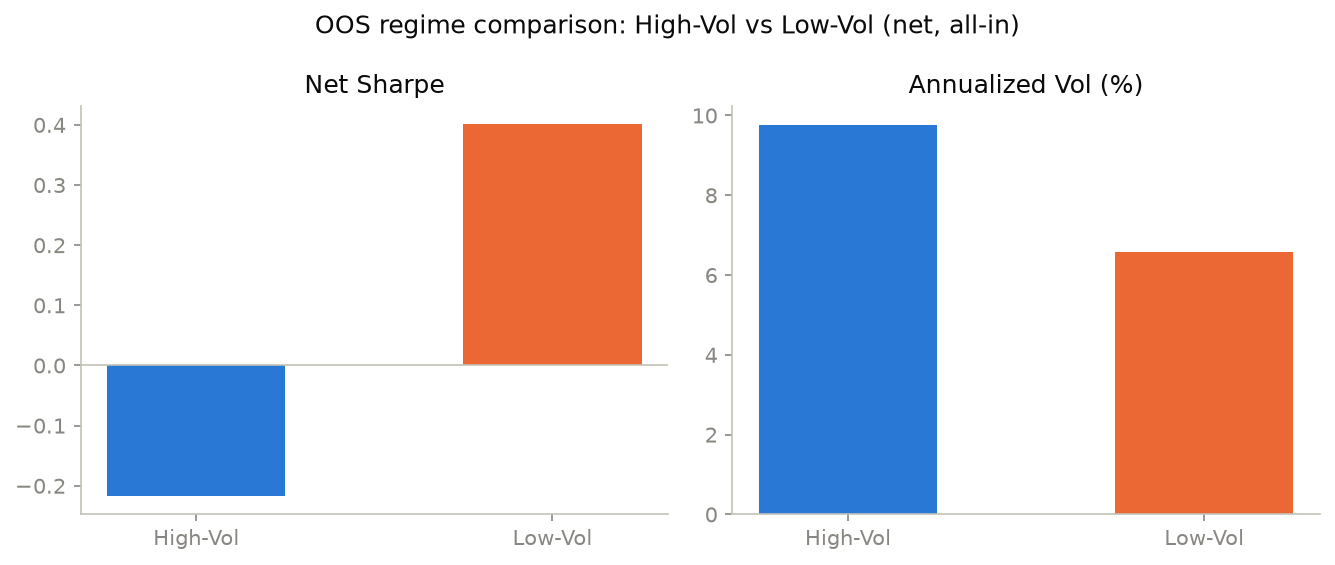

In [12]:
fig = ch.plot_regime_bar(oos_high_metrics, oos_low_metrics)
ch.show_fig(fig)


### Borrow and leverage-financing cost: quantitative disclosure

GLD and IEF are large, liquid general-collateral ETFs, assumed short-borrow fee: ~0.25–0.50%/yr on shorted notional. 

The three FX legs have different mechanics: a spot FX short requires no security borrow at all but does embed financing via swap and rollover points on any position held overnight. 
Which are excluded from the modeled cost lines the same way ETF financing is. 

In [13]:
avg_gross = oos_metrics["avg_gross_exposure_postcap"]
financed_notional_frac = max(avg_gross - 1.0, 0.0)
low_drag = financed_notional_frac * 0.005
high_drag = financed_notional_frac * 0.015

print(f"OOS average gross exposure (post-cap): {avg_gross:.2f}x")
print(f"-> average notional financed above 100%: {financed_notional_frac*100:.0f}% of capital")
print(f"-> back-of-envelope total annual financing drag at this average exposure: "
      f"~{low_drag*100:.2f}%-{high_drag*100:.2f}%/yr")
print(f"-> should mentally haircut the reported net Sharpe by roughly this much before "
      f"treating it as a deployable, all-in number.")
print()
print("This exclusion is a deliberate, disclosed simplification: the 2x gross cap "
      "bounds how large the unmodeled financing can be, which is part of why disclosure (rather than "
      "modeling) is defensible here.")


OOS average gross exposure (post-cap): 1.92x
-> average notional financed above 100%: 92% of capital
-> back-of-envelope total annual financing drag at this average exposure: ~0.46%-1.37%/yr
-> should mentally haircut the reported net Sharpe by roughly this much before treating it as a deployable, all-in number.

This exclusion is a deliberate, disclosed simplification: the 2x gross cap bounds how large the unmodeled financing can be, which is part of why disclosure (rather than modeling) is defensible here.


### Robustness 1: parameter sensitivity (6mo, 9mo, 12mo lookback)

Small, fixed set of nearby lookbacks, not a search. Reported side by side. The 12-month lookback remains primary
throughout regardless of which looks best here.


In [14]:
rows = []
for label, lb_signal in all_signals.items():
    lb_result = bt.run_backtest(prices, lb_signal)
    lb_dev = mx.compute_period_metrics(lb_result, lb_signal, DEV_START, DEV_END)
    lb_oos = mx.compute_period_metrics(lb_result, lb_signal, OOS_START, OOS_END)
    rows.append({
        "lookback": label,
        "dev_annual_return": lb_dev["net_all_in"]["annual_return"],
        "dev_sharpe": lb_dev["net_all_in"]["sharpe"],
        "oos_annual_return": lb_oos["net_all_in"]["annual_return"],
        "oos_sharpe": lb_oos["net_all_in"]["sharpe"],
    })
lookback_sensitivity_table = pd.DataFrame(rows)
lookback_sensitivity_table


,lookback,dev_annual_return,dev_sharpe,oos_annual_return,oos_sharpe
0,6mo,0.0625,0.6763,-0.0051,-0.0608
1,9mo,0.0528,0.5788,-0.0012,-0.0139
2,12mo,0.0511,0.5562,0.0022,0.0259


### Robustness 2: cost sensitivity (0.5x, 1x, 1.5x, 2x base costs, OOS, net all-in)

Fixed stress-test grid over the same unchanged strategy, not a search, showing how fragile the OOS edge is to the
cost assumption.


In [15]:
cost_sensitivity_table = mx.cost_sensitivity_table(
    bt.run_backtest, prices, primary_signal, OOS_START, OOS_END, base_tx_cost_bps=bt.TX_COST_BPS
)
cost_sensitivity_table


,cost_multiplier,gld_bps,ief_bps,eurusd_bps,gbpusd_bps,usdjpy_bps,net_annual_return,net_sharpe,net_sortino,net_calmar
0,0.5000,3.5000,1.5000,1.0000,1.0000,1.0000,0.0045,0.0541,0.0791,0.0155
1,1.0000,7.0000,3.0000,2.0000,2.0000,2.0000,0.0022,0.0259,0.0378,0.0072
2,1.5000,10.5000,4.5000,3.0000,3.0000,3.0000,-0.0002,-0.0023,-0.0033,-0.0006
3,2.0000,14.0000,6.0000,4.0000,4.0000,4.0000,-0.0025,-0.0304,-0.0442,-0.0081


### Comparison to the paper anchor

Moskowitz, Ooi & Pedersen (2012) report a diversified TSMOM strategy across about 58 futures contracts spanning
equities, bonds, currencies and commodities roughly evenly, achieving an annualized Sharpe of roughly **1.0**
with strong performance in most sub-periods and crisis alpha in 2008. 

This basket (GLD for commodity, IEF forbonds, EURUSD/GBPUSD/USDJPY for currency) samples three of those same four asset classes, but unevenly: 3 of 5
instruments are currency pair and they are not fully independent of each other since they share USD as one side of every pair. 

So this is not "5 instruments compared to 58." It is more like "3 different legs (gold, duration, a USD-bloc FX trend) held across 5 instruments" than to the paper's broad,
even-weighted cross-asset-class breadth. 

Our OOS Sharpe well below the paper's figure (see metrics tables above)
is consistent with that: the paper's edge comes substantially from breadth across many weakly-correlated trends
across and within asset classes and neither axis of that breadth is very large here.


## Appendix (exploratory, not used for headline numbers)

Correlation-adjusted equal-risk-contribution (ERC) weighting, using the trailing 60-day covariance matrix instead
of independent per-leg vol targeting. Shown here purely as a supplementary comparison against the primary method.
This section does not feed the headline metrics or any of the primary tables above.


In [16]:
result_rp = bt.run_backtest(prices, primary_signal, combo_method="risk_parity_appendix")
oos_rp_metrics = mx.compute_period_metrics(result_rp, primary_signal, OOS_START, OOS_END, notional=NOTIONAL)

comparison = pd.DataFrame({
    "Primary (inverse-vol)": oos_metrics["net_all_in"],
    "Appendix (ERC, exploratory)": oos_rp_metrics["net_all_in"],
}).T
comparison


,annual_return,annual_vol,sharpe,sortino,max_drawdown,calmar,hit_rate
Primary (inverse-vol),0.0022,0.0836,0.0259,0.0378,-0.2987,0.0072,0.5088
"Appendix (ERC, exploratory)",0.0069,0.0841,0.0818,0.1195,-0.2669,0.0258,0.5103


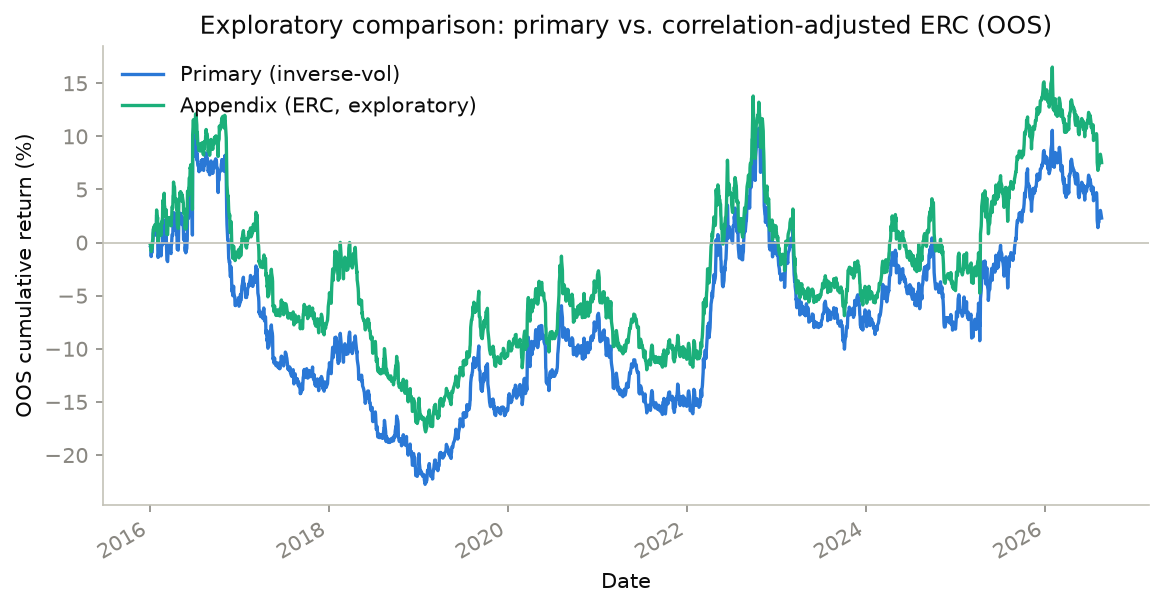

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.5))
(mx.cumulative_return(result["net_all_in_return"][result["net_all_in_return"].index >= OOS_START]) - 1).mul(100).plot(
    ax=ax, color=ch.STRATEGY_COLOR, linewidth=1.6, label="Primary (inverse-vol)")
(mx.cumulative_return(result_rp["net_all_in_return"][result_rp["net_all_in_return"].index >= OOS_START]) - 1).mul(100).plot(
    ax=ax, color=ch.AQUA, linewidth=1.6, label="Appendix (ERC, exploratory)")
ax.axhline(0, color=ch.AXIS, linewidth=0.8)
ax.set_ylabel("OOS cumulative return (%)")
ax.set_title("Exploratory comparison: primary vs. correlation-adjusted ERC (OOS)")
ax.legend(frameon=False, loc="upper left")
ch.show_fig(fig)


This section is included as a supplementary comparison. Whether ERC modestly outperforms or underperforms the primary method here is not a basis for switching the headline method.
The primary deterministic inverse-vol approach remains the reported strategy.


## Key takeaways / limitations

### **Mechanism.** 

TSMOM in a small, cross-asset-class basket (gold, duration, FX) is a real, paper-supported effect
  (Moskowitz, Ooi & Pedersen 2012), but its edge is concentrated in calmer, more persistently-trending regimes
  (see OOS Low-Vol vs. High-Vol split above) and is small relative to a fully diversified multi-instrument
  implementation of the same idea.


### **Costs.** 

The gap between gross and net-all-in OOS performance and the cost-sensitivity table show how
  much of the edge survives realistic cost assumptions.

### **Financing and borrow costs are disclosed.** 

See the quantitative back-of-envelope estimate
  above. Need to cut the reported net Sharpe by roughly that amount before treating it as
  deployable.

### **FX-leg selection is disclosed, not bias-free.** 

GBPUSD and USDJPY were added because GBP and JPY are among
  the most heavily-traded, most-held G10 currencies (BIS Triennial Survey / IMF reserve-currency share). This is independent of how they performed in this backtest.
  The selector is writing this with full hindsight over the entire sample,so should treat "these two, specifically" as
  a judgment call informed by present-day knowledge of currency markets, not a bias-free pick from the full G10
  set.

### **Three of five legs share USD exposure.** 

EURUSD, GBPUSD and USDJPY are all quoted against USD, so a
  broad-dollar cycle can push all three FX trends in the same direction. The correlation check in the Data
  section quantifies how much of a concern this is in this sample, rather than leaving it as a qualitative
  worry. This is the same category of issue as the original TLT/IEF duration overlap in an earlier version of
  this basket, though less severe.

### **Data-source limitation.** 

Gold and the govt-bond leg are sourced from GLD/IEF (ETFs) rather than back-adjusted continuous futures, because the futures history available to me stopped in 2016 and could not
  support a 10-year OOS window.  GLD/IEF have no roll or carry dynamics and different liquidity and short-borrow mechanics than a real futures position. This is a
  disclosed conceptual mismatch. All three FX legs are themselves two-vendor splices: the
  vendor CSV through 2016-12-30 concatenated with `yfinance` from 2017 onward. Each is validated at its
  boundary (`load_fx_spliced`'s sanity check) but is still a disclosed seam in the data.

### **Sample limitation.** 
The combined history starts Nov 2004 (GLD's IPO) and spans several very different rate
  and USD regimes (2004 to 2015 low and falling rates; 2016 to 2026 hiking, cutting and hiking again). This is a
  reasonably representative sample for a 10-year OOS window, but persistence claims well beyond this sample
  should still be made cautiously.


## Verdict

Conclusion, using a **pursue / monitor / paper trade / reject** framework, backed by the computed OOS net Sharpe and drawdown, with the main evidence, biggest limitation and the mechanism that would support or undermine persistence going forward.


In [18]:
# verdict, evidence_text, limitation_text and mechanism_text were computed
# once, earlier (Findings > "Verdict determination"), from the actual OOS
# net-all-in Sharpe and drawdown. Reused here unchanged so the notebook's
# verdict determination and this closing statement can never drift apart.
print(f"VERDICT: {verdict}")
print()
print(f"Main evidence: {evidence_text}")
print()
print(f"Biggest limitation: {limitation_text}")
print()
print(f"Mechanism for/against persistence: {mechanism_text}")


VERDICT: PAPER TRADE

Main evidence: OOS (2016-2026) net-all-in Sharpe = 0.03, Sortino = 0.04, annualized return = 0.2%, max drawdown = -29.9%. For comparison, the static 1/5-each benchmark achieved net Sharpe 0.73 over the same window. The active strategy did not clear its own costs relative to a passive hold.

Biggest limitation: the gross signal (see metrics tables above) is partly consumed by transaction costs, expense ratios and the disclosed but unmodeled financing drag once realistic costs are applied. The cost-sensitivity table below shows how much of the net edge survives across the tested 0.5x to 2x cost range, which shows how robust the OOS edge is to cost-assumption uncertainty.

Mechanism for/against persistence: TSMOM's edge (Moskowitz, Ooi & Pedersen 2012) is empirically strongest when held across many weakly-correlated trends. This basket holds five instruments but effectively fewer independent bets. The three FX legs (EURUSD, GBPUSD, USDJPY) run a mean absolute pairwis